In [1]:
import torch
from torch import nn 
from d2l import torch as d2l

In [2]:
import ptbData.bertModel.wikiDataLoad
import ptbData.bertModel.bertModel

In [3]:
batch_size, max_len = 512, 64 
train_iter, vocab = ptbData.bertModel.wikiDataLoad.load_data_wiki(batch_size, max_len)

In [4]:
net = ptbData.bertModel.BERTModel(len(vocab), num_hiddens=128, ffn_num_input=128, ffn_num_hiddens=256, 
                    num_heads=2, num_layers=2, dropout=0.2, key_size=128, query_size=128, value_size=128,
                      hid_in_features=128, mlm_in_features=128, nsp_in_features=128) 
devices = d2l.try_all_gpus() 
loss = nn.CrossEntropyLoss(reduction='none')

In [5]:
def big_loss(bert,loss,vocab_size,tokens_X,segments_X,valid_lens_x,pred_position_X,mlm_lens_X,mlm_Y,nsp_y):
    # 1. 检查输入是否越界
    assert tokens_X.max() < vocab_size, "tokens_X 越界了！"
    assert pred_position_X.max() < 64, "预测位置越界了！"
    
    _, mlm_Y_hat, nsp_Y_hat = bert(tokens_X, segments_X, valid_lens_x, pred_position_X)
    
    # 2. 检查前向传播是否产生 NaN
    if torch.isnan(mlm_Y_hat).any() or torch.isnan(nsp_Y_hat).any():
        print("❌ 警告：前向传播产生了 NaN！")
    
    mlm_l = loss(mlm_Y_hat.reshape(-1, vocab_size), mlm_Y.reshape(-1))
    mlm_l = (mlm_l * mlm_lens_X.reshape(-1)).sum() / (mlm_lens_X.sum() + 1e-8)
    nsp_l = loss(nsp_Y_hat, nsp_y).mean()
    
    # 3. 检查 Loss 是否变成 NaN
    if torch.isnan(mlm_l) or torch.isnan(nsp_l):
        print("❌ 警告：Loss 变成了 NaN！")
        
    l = mlm_l + nsp_l
    return mlm_l, nsp_l, l

In [6]:
def train_bert(train_iter, net, loss, vocab_size, devices, num_steps):  
    net = net.to(devices[0])
    trainer = torch.optim.Adam(net.parameters(), lr=1e-3) 
    step, timer = 0, d2l.Timer() 
    animator = d2l.Animator(xlabel='step', ylabel='loss',  xlim=[1, num_steps], legend=['mlm', 'nsp']) # 遮蔽语言模型损失的和,下一句预测任务损失的和,句子对的数量,计数 
    metric = d2l.Accumulator(4) 
    num_steps_reached = False 
    while step < num_steps and not num_steps_reached:  
        for tokens_X, segments_X, valid_lens_x, pred_positions_X,\
              mlm_weights_X, mlm_Y, nsp_y in train_iter: 
            tokens_X = tokens_X.to(devices[0]) 
            segments_X = segments_X.to(devices[0]) 
            valid_lens_x = valid_lens_x.to(devices[0]) 
            pred_positions_X = pred_positions_X.to(devices[0]) 
            mlm_weights_X = mlm_weights_X.to(devices[0]) 
            mlm_Y, nsp_y = mlm_Y.to(devices[0]), nsp_y.to(devices[0]) 
            trainer.zero_grad() 
            timer.start() 
            mlm_l, nsp_l, l = big_loss(net, loss, vocab_size, tokens_X, segments_X, valid_lens_x, pred_positions_X, mlm_weights_X, mlm_Y, nsp_y) 
            l.backward() 
            trainer.step() 
            metric.add(mlm_l, nsp_l, tokens_X.shape[0], 1) 
            timer.stop() 
            animator.add(step + 1,  (metric[0] / metric[3], metric[1] / metric[3])) 
            step += 1 
            if step == num_steps:  
                num_steps_reached = True 
                break 
    print(f'MLM loss {metric[0] / metric[3]:.3f}, '  f'NSP loss {metric[1] / metric[3]:.3f}') 
    print(f'{metric[2] / timer.sum():.1f} sentence pairs/sec on '  f'{str(devices)}')

MLM loss 7.391, NSP loss 0.710
5362.5 sentence pairs/sec on [device(type='cuda', index=0), device(type='cuda', index=1), device(type='cuda', index=2)]


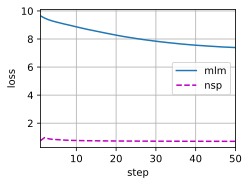

In [7]:
train_bert(train_iter, net, loss, len(vocab), devices, 50)

In [8]:
def test_predict(net,tokens_a,tokens_b=None):
    tokens,segments=d2l.get_tokens_and_segments(tokens_a,tokens_b)
    tokens=torch.tensor(vocab[tokens],dtype=torch.long,device=devices[0]).unsqueeze(0)
    segments=torch.tensor(segments,dtype=torch.long,device=devices[0]).unsqueeze(0)
    valid_lens=torch.tensor(len(tokens),dtype=torch.long,device=devices[0]).unsqueeze(0)
    encoder_X,_,_=net(tokens, segments, valid_lens, None)
    return encoder_X

In [10]:
tokens_a = ['a', 'crane', 'is', 'flying'] 
encoded_text = test_predict(net, tokens_a) # 词元:'<cls>','a','crane','is','flying','<sep>' 
encoded_text_cls = encoded_text[:, 0, :] 
encoded_text_crane = encoded_text[:, 2, :] 
encoded_text.shape, encoded_text_cls.shape, encoded_text_crane[0][:]

torch.Size([12])
torch.Size([12])


(torch.Size([1, 6, 128]),
 torch.Size([1, 128]),
 tensor([ -0.6755,  -9.9830,   3.9069,  -4.7975,   8.9905,   8.1727,   4.6620,
           0.4282,  -6.1001,   0.3957,  12.0836,  -9.7066, -17.3618,   2.7197,
           9.3773,   6.5581, -13.4641,  -7.3645,  -4.0934,  -6.6861,   7.1133,
           4.5721,  -0.7017,  -6.5109,  -1.5314,   4.4130,   3.6988,   4.3611,
           2.8144,  -4.3472,   3.4931,   3.2886,   6.3790,  -6.2415,   4.7279,
          -0.3555, -12.1156,   1.8553,   4.5955,  -3.3945,   1.5085,   5.5262,
          -9.3225,   6.6360,   7.3140,  -3.1087,   1.3927,   2.5283,  -2.2000,
          -1.0364,  -2.1092,  -1.7494,  -9.9413,  -3.8134,  -6.1448,   1.1581,
         -10.6968,   2.4404,  -2.4289,   5.6336,  10.1636,  -0.7393,   6.7233,
           4.7062,  -8.2821,   6.3705,   1.4858,   3.1525,   9.1974,   0.7066,
           0.6938,   7.9898,   6.2381,   4.2037,  -1.5867,   1.4818,   3.5453,
          -2.0922,  -6.7561,   1.9213,  -7.9107,  -1.5055,  -2.9731,   2.3292,
   

In [11]:
tokens_a, tokens_b = ['a', 'crane', 'driver', 'came'], ['he', 'just', 'left'] 
encoded_pair = test_predict(net, tokens_a, tokens_b) # 词元:'<cls>','a','crane','driver','came','<sep>','he','just', # 'left','<sep>' 
encoded_pair_cls = encoded_pair[:, 0, :] 
encoded_pair_crane = encoded_pair[:, 2, :] 
encoded_pair.shape, encoded_pair_cls.shape, encoded_pair_crane[0][:3]

torch.Size([20])
torch.Size([20])


(torch.Size([1, 10, 128]),
 torch.Size([1, 128]),
 tensor([-2.5482, -9.2488,  4.3779], device='cuda:0', grad_fn=<SliceBackward0>))